# Bước 5. Phân lớp dựa trên luật kết hợp (CBA, CMAR)

**Câu hỏi của bước 5.** Với mỗi cặp (người dùng, sản phẩm) mà người dùng đã từng mua trong các đơn prior,
dự đoán sản phẩm đó có xuất hiện trong đơn kế tiếp (đơn train) hay không, bằng phân lớp dựa trên luật kết hợp
(CBA làm mô hình chính, CMAR mở rộng), so với cây quyết định tiêu chí entropy và LightGBM.

**Cách chạy.** Notebook có hai phần.
- **Phần A (chạy trước, nhanh):** tạo bảng nhãn và chia người dùng, xuất Parquet để bàn giao cho B1 (đo mất cân bằng nhãn) và B2 (rời rạc hóa theo nhãn mới).
- **Phần B:** thuộc tính, rời rạc hóa, CBA, CMAR, mô hình đối chứng, đánh giá trên holdout, phân tích lỗi.

**Nguyên tắc chống rò rỉ dữ liệu** (task T45 sẽ kiểm tra độc lập):
1. Nhãn chỉ lấy từ đơn train; thuộc tính chỉ lấy từ đơn prior (cộng khoảng cách ngày tới đơn cần dự đoán).
2. Chia theo `user_id`: một người dùng chỉ thuộc một trong ba phần fit, valid, holdout.
3. Tỷ lệ mua lại theo sản phẩm, gian hàng, ngành hàng; điểm cắt rời rạc hóa; luật lớp: chỉ học trên phần fit.
4. Siêu tham số và ngưỡng quyết định: chọn trên valid. Holdout chỉ dùng **một lần** ở mục B8.

## 0. Cấu hình

In [1]:
import os, sys, json, time, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# SỬA ĐƯỜNG DẪN NÀY cho đúng thư mục chung của nhóm trên Drive
REPO_DIR = Path(os.environ.get("B5_REPO_DIR", "/content/drive/MyDrive/Nhom04_ADM/repo"))
DATA_DIR = Path(os.environ.get("B5_DATA_DIR", REPO_DIR / "data" / "processed"))     # 5 tệp Parquet của B2
OUT_DIR = Path(os.environ.get("B5_OUT_DIR", REPO_DIR / "data" / "processed" / "b5"))
FIG_DIR = Path(os.environ.get("B5_FIG_DIR", REPO_DIR / "reports" / "figures"))
# Tệp luật cấp gian hàng do B4 xuất (để None nếu chưa có: notebook sẽ tự khai thác luật dự phòng)
RULES4_PATH = os.environ.get("B5_RULES4_PATH", str(REPO_DIR / "data" / "processed" / "rules_aisle.csv"))

sys.path.insert(0, str(Path(os.environ.get("B5_SRC_DIR", REPO_DIR / "src"))))
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

PARAMS = {
    "holdout_frac": 0.20, "valid_frac": 0.10,          # 70% fit, 10% valid, 20% holdout theo người dùng
    "max_intervals": 5,                                # số khoảng tối đa mỗi thuộc tính (xem discretize.py)
    "cba_min_support": 0.01, "cba_min_confidence": 0.50, "cba_max_len": 3, "cba_prune": True,
    "cmar_coverage_delta": 4,
    "run_cmar": True,
    "n_boot": 200,
}
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)
print("DATA_DIR =", DATA_DIR)

Mounted at /content/drive
Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3
DATA_DIR = /content/drive/MyDrive/Nhom04_ADM/repo/data/processed


# PHẦN A. Nhãn và chia tập (bàn giao cho B1, B2)

## A1. Đọc dữ liệu của bước 2 và kiểm tra đầu vào
Mọi dòng có cột "Kỳ vọng" phải **Đạt**. Đặc biệt chú ý dòng *Đơn prior không có dòng sản phẩm nào*: bảng
`order_products_prior_sample` có đúng 2.066.000 dòng (một số tròn), nên cần xác nhận bảng không bị cắt bớt.
Nếu dòng này khác 0, báo ngay cho Thiên Trang trước khi đi tiếp.

In [2]:
from b5_classification import labels as L

d = L.load_b2_data(DATA_DIR)
for name in ["orders_prior", "orders_train", "op_prior", "op_train", "products"]:
    print(f"{name:13s}", getattr(d, name).shape)
integrity = L.integrity_report(d)
integrity

orders_prior  (206657, 6)
orders_train  (13121, 6)
op_prior      (2066000, 4)
op_train      (139019, 4)
products      (49688, 6)


,Kiểm tra,Giá trị,Kỳ vọng,Đạt
0,Số người dùng có đơn prior,13121,NaN,
1,Số người dùng có đơn train,13121,NaN,
2,Người dùng có đơn train nhưng không có lịch sử...,0,0.0,Đạt
3,Người dùng có nhiều hơn một đơn train,0,0.0,Đạt
4,Dòng sản phẩm prior trỏ tới đơn không có trong...,0,0.0,Đạt
5,Dòng sản phẩm train trỏ tới đơn không có trong...,0,0.0,Đạt
6,Đơn prior không có dòng sản phẩm nào,0,0.0,Đạt
7,Đơn train không có dòng sản phẩm nào,0,0.0,Đạt
8,"Cặp (order_id, product_id) trùng trong prior",0,0.0,Đạt
9,"Cặp (order_id, product_id) trùng trong train",0,0.0,Đạt


## A2. Tạo bảng cặp và nhãn (task T34)
- Đối tượng: mỗi cặp (`user_id`, `product_id`) người dùng đã mua trong đơn prior, chỉ lấy người dùng có đơn train.
- Nhãn bằng 1 nếu sản phẩm có trong đơn train của người dùng đó.
- **Kiểm tra chéo:** số cặp nhãn 1 phải bằng số dòng của đơn train có `reordered = 1`.
- `ty_le_dong_train_la_san_pham_moi`: phần sản phẩm trong đơn train mà người dùng chưa từng mua. Các sản phẩm này
  nằm ngoài tập ứng viên, nên mô hình không thể "đoán" ra chúng; cần nêu là giới hạn của bài toán.

In [3]:
pairs, label_stats = L.build_labels(d)
assert label_stats["kiem_tra_nhan_1_bang_reordered_train"], "Số nhãn 1 không khớp reordered của đơn train"
pd.Series(label_stats, name="giá trị").to_frame()

,giá trị
so_nguoi_dung,13121
so_cap,848233
so_cap_nhan_1,82657
so_cap_nhan_0,765576
ty_le_nhan_1,0.097446
ty_le_0_tren_1,9.262083
so_cap_trung_binh_moi_nguoi,64.646978
so_dong_san_pham_trong_don_train,139019
so_dong_train_reordered_1,82657
ty_le_dong_train_la_san_pham_moi,0.405427


## A3. Chia người dùng thành fit, valid, holdout (task T38)

In [4]:
user_split = L.split_users(pairs["user_id"].to_numpy(), PARAMS["holdout_frac"], PARAMS["valid_frac"], SEED)
L.assert_no_user_overlap(user_split)
split_table = L.split_summary(pairs, user_split)
split_table

,so_nguoi_dung,so_cap,so_nhan_1,ty_le_nhan_1
fit,9185,591403,57865,0.097844
valid,1312,85877,8331,0.097011
holdout,2624,170953,16461,0.096290
tong,13121,848233,82657,0.097446


## A4. Xuất tệp bàn giao
- `b5_pairs_labels.parquet`: `user_id`, `product_id`, `label`, `split` → B1 dùng đo mất cân bằng (thay cho `reordered` ở mục 6 của EDA).
- `b5_user_split.parquet`: `user_id`, `split` → B2 chỉ học điểm cắt trên người dùng có `split == "fit"`.
- `b5_label_stats.json`: các con số ở A2, A3 để viết báo cáo.

In [5]:
pairs_out = pairs.merge(user_split, on="user_id", how="left")
pairs_out.to_parquet(OUT_DIR / "b5_pairs_labels.parquet", index=False)
user_split.to_parquet(OUT_DIR / "b5_user_split.parquet", index=False)
with open(OUT_DIR / "b5_label_stats.json", "w", encoding="utf-8") as fh:
    json.dump({k: (float(v) if isinstance(v, (np.floating, float)) else (bool(v) if isinstance(v, (bool, np.bool_)) else int(v)))
               for k, v in label_stats.items()}, fh, ensure_ascii=False, indent=2)
split_table.to_csv(OUT_DIR / "b5_split_table.csv")
print("Đã xuất vào", OUT_DIR)

Đã xuất vào /content/drive/MyDrive/Nhom04_ADM/repo/data/processed/b5


# PHẦN B. Mô hình hóa

## B1. Thuộc tính cho từng cặp (task T37)
Thuộc tính chỉ lấy từ đơn prior. Tỷ lệ mua lại theo sản phẩm, gian hàng, ngành hàng chỉ tính trên người dùng fit.

In [6]:
from b5_classification import features as F

df = F.build_feature_table(d.orders_prior, d.op_prior, d.orders_train, d.products, pairs, user_split)
BASE_FEATURES = list(F.FEATURE_DESCRIPTIONS)
print(df.shape)
F.feature_summary(df, BASE_FEATURES)

(848233, 19)


,trung_vi_nhan_0,trung_vi_nhan_1,ty_le_thieu,mo_ta
up_n_bought,1.000000,3.000000,0.0,Số đơn prior mà người dùng đã mua sản phẩm
up_rate,0.083333,0.250000,0.0,Tỷ lệ đơn prior của người dùng có chứa sản phẩ...
up_orders_since_last,5.000000,1.000000,0.0,Số đơn prior đã trôi qua kể từ lần cuối mua sả...
up_days_since_last,78.000000,29.000000,0.0,Số ngày ước tính từ lần cuối mua sản phẩm tới ...
up_mean_cart_pos,7.500000,6.750000,0.0,Vị trí trung bình khi thêm sản phẩm vào giỏ
u_n_orders,19.000000,12.000000,0.0,Số đơn prior của người dùng
u_mean_basket,11.300000,12.400000,0.0,Số sản phẩm trung bình mỗi đơn của người dùng
u_mean_gap,11.350000,13.260870,0.0,Khoảng cách trung bình (ngày) giữa hai đơn liê...
u_reorder_ratio,0.558386,0.573529,0.0,Tỷ lệ dòng mua lại của người dùng (không tính ...
u_days_to_target,11.000000,14.000000,0.0,Số ngày từ đơn prior cuối tới đơn cần dự đoán ...


## B2. Nối luật của bước 4 thành thuộc tính `r4_lift`
Nếu đã có tệp luật cấp gian hàng của B4 (`RULES4_PATH`), dùng luật đó. Nếu chưa có, khai thác luật **dự phòng**
trên đơn prior của người dùng fit (minsup 2%, minconf 50%, lift > 1) và ghi rõ trong báo cáo là luật dự phòng.

In [7]:
from b5_classification import step4_link as S4

if RULES4_PATH and Path(RULES4_PATH).exists():
    rules4 = S4.load_step4_rules(RULES4_PATH, d.products, level="aisle")
    rules4_source = "B4"
else:
    fit_users = user_split.loc[user_split.split == "fit", "user_id"]
    fit_orders = d.orders_prior[d.orders_prior.user_id.isin(fit_users)]["order_id"]
    baskets = (d.op_prior[d.op_prior.order_id.isin(fit_orders)]
               .merge(d.products[["product_id", "aisle_id"]], on="product_id")[["order_id", "aisle_id"]]
               .drop_duplicates())
    rules4 = S4.mine_aisle_rules(baskets, "aisle_id", min_support=0.02, min_confidence=0.5)
    rules4_source = "dự phòng (tự khai thác trên người dùng fit)"
print("Nguồn luật:", rules4_source, "| số luật dùng được:", len(rules4))
df["r4_lift"] = S4.r4_lift_feature(df[["user_id", "product_id"]], d.orders_prior, d.op_prior, d.products, rules4).to_numpy()
FEATURES = BASE_FEATURES + ["r4_lift"]
print("Tỷ lệ cặp có ít nhất một luật khớp:", (df["r4_lift"] > 1).mean().round(4))
df.groupby(df["r4_lift"] > 1)["label"].agg(["size", "mean"]).rename(index={False: "không khớp luật", True: "khớp luật"})

Nguồn luật: B4 | số luật dùng được: 25
Tỷ lệ cặp có ít nhất một luật khớp: 0.1971


,size,mean
r4_lift,,
không khớp luật,681034,0.088173
khớp luật,167199,0.135216


## B3. Rời rạc hóa theo entropy (Fayyad và Irani), chỉ học trên phần fit
Mỗi thuộc tính có tối đa `max_intervals` khoảng. Điểm cắt được lưu ra `b5_cutpoints.json` để B2 trình bày ở mục 4.3.

In [8]:
from b5_classification.discretize import Discretizer

fit = df[df.split == "fit"].reset_index(drop=True)
valid = df[df.split == "valid"].reset_index(drop=True)
hold = df[df.split == "holdout"].reset_index(drop=True)
y_fit, y_valid, y_hold = fit.label.to_numpy(), valid.label.to_numpy(), hold.label.to_numpy()

disc = Discretizer(max_intervals=PARAMS["max_intervals"]).fit(fit, FEATURES, y_fit)
disc.to_json(OUT_DIR / "b5_cutpoints.json")
Xc_fit, Xc_valid, Xc_hold = disc.transform(fit), disc.transform(valid), disc.transform(hold)
LABELERS = {f: disc.interval_labels(f) for f in FEATURES}
disc_table = disc.summary(fit, y_fit)
disc_table.to_csv(OUT_DIR / "b5_discretization.csv", index=False)
print({f: len(c) + 1 for f, c in disc.cuts.items()})
disc_table

{'up_n_bought': 5, 'up_rate': 5, 'up_orders_since_last': 5, 'up_days_since_last': 5, 'up_mean_cart_pos': 5, 'u_n_orders': 5, 'u_mean_basket': 5, 'u_mean_gap': 5, 'u_reorder_ratio': 5, 'u_days_to_target': 5, 'p_reorder_rate': 5, 'a_reorder_rate': 5, 'd_reorder_rate': 5, 'r4_lift': 5}


,thuoc_tinh,ma,khoang,so_cap,ty_le_nhan_1
0,up_n_bought,0,"< 1,5",355932,0.047411
1,up_n_bought,1,"[1,5; 2,5)",97146,0.104060
2,up_n_bought,2,"[2,5; 6,5)",98423,0.181645
3,up_n_bought,3,"[6,5; 15,5)",31293,0.292334
4,up_n_bought,4,">= 15,5",8609,0.447787
...,...,...,...,...,...
65,r4_lift,0,"< 1,181",477831,0.088469
66,r4_lift,1,"[1,181; 1,446)",49481,0.143085
67,r4_lift,2,"[1,446; 1,457)",9643,0.102458
68,r4_lift,3,"[1,457; 1,486)",8931,0.197962


## B4. CBA theo cấu hình gốc của bài báo (task T39)
Cấu hình đúng như Liu, Hsu và Ma (1998): minsup 1%, minconf 50%, cắt tỉa lỗi bi quan, học trên toàn bộ phần fit.
Ô in ra số luật lớp 1 trong bộ phân lớp: với nhãn 1 hiếm, con số này cho biết CBA gốc có học được luật cho lớp cần dự đoán hay không.

In [9]:
from b5_classification.cba import CBAClassifier
from b5_classification.evaluation import classification_metrics

def n_class1(rules, classes):
    return int(sum(classes[r["cls_idx"]] == 1 for r in rules))

def cba_summary(m):
    return {"so_condset_pho_bien": m.n_condsets_, "so_CAR": m.n_cars_, "so_luat_sau_cat_tia": m.n_rules_after_prune_,
            "so_luat_trong_bo_phan_lop": len(m.rules_), "so_luat_lop_1_trong_bo_phan_lop": n_class1(m.rules_, m.classes_),
            "lop_mac_dinh": int(m.classes_[m.default_idx_]), **{k: round(v, 2) for k, v in m.timing_.items()}}

cba = CBAClassifier(PARAMS["cba_min_support"], PARAMS["cba_min_confidence"], PARAMS["cba_max_len"],
                    prune=PARAMS["cba_prune"]).fit(Xc_fit, y_fit)
cba_info = cba_summary(cba)
print(cba_info)
print("Valid:", {k: round(v, 4) for k, v in classification_metrics(y_valid, cba.predict(Xc_valid), cba.predict_score(Xc_valid)).items()})

{'so_condset_pho_bien': 9607, 'so_CAR': 9607, 'so_luat_sau_cat_tia': 1803, 'so_luat_trong_bo_phan_lop': 1426, 'so_luat_lop_1_trong_bo_phan_lop': 0, 'lop_mac_dinh': 1, 'rule_generation_s': 3.25, 'pruning_s': 0.32, 'classifier_building_s': 7.04}
Valid: {'accuracy': 0.9035, 'precision': 0.5338, 'recall': 0.0408, 'f1': 0.0758, 'ty_le_du_doan_1': 0.0074, 'pr_auc': np.float64(0.3022), 'roc_auc': np.float64(0.7892)}


## B4b. Xử lý mất cân bằng nhãn
CBA chọn luật để giảm tổng số lỗi trên dữ liệu huấn luyện. Khi khoảng 90% số cặp có nhãn 0, phương án ít lỗi nhất là
dùng luật lớp 0 và để lớp 1 làm lớp mặc định, nên bộ phân lớp gốc gần như không có luật cho lớp 1. Hai cách xử lý được thử:

1. **minsup theo lớp** (Liu, Ma & Wong, 2000): ngưỡng hỗ trợ của lớp c bằng minsup × tỷ lệ của lớp c.
2. **Cân bằng lại phần fit bằng lấy mẫu dưới lớp 0** (giữ mọi cặp nhãn 1, lấy ngẫu nhiên cùng số cặp nhãn 0, hạt giống 42).
   Chỉ phần fit bị lấy mẫu; valid và holdout giữ nguyên phân phối thật. Điểm cắt rời rạc hóa vẫn học trên toàn bộ phần fit.

Cả hai được so trên **valid**; phương án tốt hơn trở thành mô hình CBA chính ở các bước sau.

In [10]:
rng_bal = np.random.default_rng(SEED)
pos_idx, neg_idx = np.where(y_fit == 1)[0], np.where(y_fit == 0)[0]
bal_idx = np.sort(np.concatenate([pos_idx, rng_bal.choice(neg_idx, size=len(pos_idx), replace=False)]))
Xc_bal, y_bal = Xc_fit.iloc[bal_idx].reset_index(drop=True), y_fit[bal_idx]
print("Phần fit cân bằng:", len(y_bal), "cặp, tỷ lệ nhãn 1 =", round(y_bal.mean(), 4))

cba_ms = CBAClassifier(PARAMS["cba_min_support"], PARAMS["cba_min_confidence"], PARAMS["cba_max_len"],
                       prune=PARAMS["cba_prune"], class_minsup=True).fit(Xc_fit, y_fit)
cba_bal = CBAClassifier(PARAMS["cba_min_support"], PARAMS["cba_min_confidence"], PARAMS["cba_max_len"],
                        prune=PARAMS["cba_prune"]).fit(Xc_bal, y_bal)
cba_ms_info, cba_bal_info = cba_summary(cba_ms), cba_summary(cba_bal)
from b5_classification.baselines import best_f1_threshold

imb = []
for name, m in [("CBA gốc", cba), ("CBA minsup theo lớp", cba_ms), ("CBA cân bằng", cba_bal)]:
    s = m.predict_score(Xc_valid)
    thr, f1_thr = best_f1_threshold(y_valid, s)
    met = classification_metrics(y_valid, m.predict(Xc_valid), s)
    imb.append({"cau_hinh": name, "so_luat_bo_phan_lop": len(m.rules_), "so_luat_lop_1": n_class1(m.rules_, m.classes_),
                "f1_nhan_goc": met["f1"], "f1_nguong_valid": f1_thr, "pr_auc": met["pr_auc"], "roc_auc": met["roc_auc"]})
imb = pd.DataFrame(imb)
imb.to_csv(OUT_DIR / "b5_imbalance_valid.csv", index=False)
imb

Phần fit cân bằng: 115730 cặp, tỷ lệ nhãn 1 = 0.5


,cau_hinh,so_luat_bo_phan_lop,so_luat_lop_1,f1_nhan_goc,f1_nguong_valid,pr_auc,roc_auc
0,CBA gốc,1426,0,0.075825,0.371416,0.302179,0.789250
1,CBA minsup theo lớp,1485,0,0.075825,0.371835,0.302243,0.789267
2,CBA cân bằng,1295,658,0.351172,0.397577,0.353192,0.805990


### Độ nhạy theo minsup và cắt tỉa (đánh giá trên valid, không đụng holdout)

In [11]:
sens = []
for data_name, Xtr, ytr in [("gốc", Xc_fit, y_fit), ("cân bằng", Xc_bal, y_bal)]:
    for ms in [0.005, 0.01, 0.02]:
        for pr in [False, True]:
            m = CBAClassifier(ms, 0.5, PARAMS["cba_max_len"], prune=pr).fit(Xtr, ytr)
            s = m.predict_score(Xc_valid)
            met = classification_metrics(y_valid, m.predict(Xc_valid), s)
            sens.append({"du_lieu_huan_luyen": data_name, "minsup": ms, "cat_tia": pr, "so_CAR": m.n_cars_,
                         "so_luat_sau_cat_tia": m.n_rules_after_prune_, "so_luat_bo_phan_lop": len(m.rules_),
                         "f1_nguong_valid": best_f1_threshold(y_valid, s)[1], "pr_auc": met["pr_auc"],
                         "thoi_gian_s": sum(m.timing_.values())})
sens = pd.DataFrame(sens)
sens.to_csv(OUT_DIR / "b5_cba_sensitivity.csv", index=False)
sens

,du_lieu_huan_luyen,minsup,cat_tia,so_CAR,so_luat_sau_cat_tia,so_luat_bo_phan_lop,f1_nguong_valid,pr_auc,thoi_gian_s
0,gốc,0.005,False,14723,14723,1995,0.371452,0.302245,15.888319
1,gốc,0.005,True,14723,2375,1841,0.371452,0.302297,16.603712
2,gốc,0.010,False,9607,9607,1520,0.371416,0.302122,12.615493
3,gốc,0.010,True,9607,1803,1426,0.371416,0.302179,10.755303
4,gốc,0.020,False,5344,5344,998,0.374624,0.302637,8.132633
5,gốc,0.020,True,5344,1185,951,0.374624,0.302654,8.745663
6,cân bằng,0.005,False,13350,13350,1842,0.399774,0.350488,2.583133
7,cân bằng,0.005,True,13350,3768,1794,0.399774,0.350483,2.593489
8,cân bằng,0.010,False,8050,8050,1330,0.397595,0.353192,2.751425
9,cân bằng,0.010,True,8050,2553,1295,0.397577,0.353192,2.364547


## B5. CMAR (mở rộng, task T41): cấu hình gốc và bản học trên phần fit cân bằng

In [12]:
from b5_classification.cmar import CMARClassifier

def cmar_summary(m):
    return {"so_luat_ung_vien": m.n_candidate_rules_, "sau_cat_tia_luat_tong_quat": m.n_after_general_,
            "sau_kiem_dinh_chi_binh_phuong": m.n_after_chi2_, "sau_do_phu_csdl": m.n_rules_,
            "so_luat_lop_1": int((m.rules_["cls_idx"] == int(np.where(m.classes_ == 1)[0][0])).sum()),
            "thoi_gian_s": round(m.timing_["total_fit_s"], 2)}

cmar = cmar_bal = None
cmar_info = cmar_bal_info = None
if PARAMS["run_cmar"]:
    args = (PARAMS["cba_min_support"], PARAMS["cba_min_confidence"], PARAMS["cba_max_len"])
    cmar = CMARClassifier(*args, coverage_delta=PARAMS["cmar_coverage_delta"]).fit(Xc_fit, y_fit)
    cmar_bal = CMARClassifier(*args, coverage_delta=PARAMS["cmar_coverage_delta"]).fit(Xc_bal, y_bal)
    cmar_info, cmar_bal_info = cmar_summary(cmar), cmar_summary(cmar_bal)
    print("CMAR gốc:", cmar_info)
    print("CMAR cân bằng:", cmar_bal_info)

CMAR gốc: {'so_luat_ung_vien': 9607, 'sau_cat_tia_luat_tong_quat': 1785, 'sau_kiem_dinh_chi_binh_phuong': 1738, 'sau_do_phu_csdl': 1721, 'so_luat_lop_1': 0, 'thoi_gian_s': 9.67}
CMAR cân bằng: {'so_luat_ung_vien': 8052, 'sau_cat_tia_luat_tong_quat': 2482, 'sau_kiem_dinh_chi_binh_phuong': 2481, 'sau_do_phu_csdl': 1881, 'so_luat_lop_1': 986, 'thoi_gian_s': 1.48}


## B6. Mô hình đối chứng (task T40)

In [13]:
from b5_classification import baselines as B

tree_disc, tree_disc_grid, t_tree_disc = B.fit_decision_tree(Xc_fit, y_fit, Xc_valid, y_valid, seed=SEED)
Xr_fit, Xr_valid, Xr_hold = (x[FEATURES].fillna(-1) for x in (fit, valid, hold))
tree_raw, tree_raw_grid, t_tree_raw = B.fit_decision_tree(Xr_fit, y_fit, Xr_valid, y_valid, seed=SEED)
lgbm, t_lgbm = B.fit_lightgbm(fit[FEATURES], y_fit, valid[FEATURES], y_valid, seed=SEED)
one_rule = B.SingleFeatureRule("up_rate").fit(valid, y_valid)
print("Cây (mã khoảng) chọn max_depth =", tree_disc.get_depth(), "| Cây (gốc) max_depth =", tree_raw.get_depth(),
      "| LightGBM số cây =", lgbm.best_iteration_, "| ngưỡng up_rate =", round(one_rule.threshold_, 4))
pd.concat([tree_disc_grid.assign(du_lieu="mã khoảng"), tree_raw_grid.assign(du_lieu="giá trị gốc")])

Cây (mã khoảng) chọn max_depth = 10 | Cây (gốc) max_depth = 8 | LightGBM số cây = 64 | ngưỡng up_rate = 0.3371


,max_depth,pr_auc_valid,so_la,thoi_gian_s,du_lieu
0,4,0.327402,16,0.788389,mã khoảng
1,6,0.360856,64,1.102188,mã khoảng
2,8,0.371624,244,1.395874,mã khoảng
3,10,0.372398,751,1.582325,mã khoảng
4,12,0.369490,1737,1.791010,mã khoảng
0,4,0.328508,16,2.599329,giá trị gốc
1,6,0.364236,64,4.576584,giá trị gốc
2,8,0.375211,242,4.548980,giá trị gốc
3,10,0.375052,741,6.790557,giá trị gốc
4,12,0.365695,1710,7.624805,giá trị gốc


## B7. Chọn ngưỡng quyết định trên valid
CBA và CMAR có nhãn dự đoán riêng (luật đầu tiên khớp, hoặc nhóm luật mạnh nhất). Báo cáo cả **nhãn gốc** của thuật
toán và **ngưỡng theo F1** chọn trên valid áp lên điểm số. Một điểm số gần như hằng số trên valid (ít hơn 3 giá trị khác
nhau) không có ngưỡng ý nghĩa, nên chỉ báo cáo nhãn gốc.

In [14]:
def score_fns():
    fns = {
        "CBA gốc": (lambda X, Xc: cba.predict_score(Xc)),
        "CBA cân bằng": (lambda X, Xc: cba_bal.predict_score(Xc)),
        "Cây entropy (mã khoảng)": (lambda X, Xc: tree_disc.predict_proba(Xc)[:, 1]),
        "Cây entropy (giá trị gốc)": (lambda X, Xc: tree_raw.predict_proba(X[FEATURES].fillna(-1))[:, 1]),
        "LightGBM": (lambda X, Xc: lgbm.predict_proba(X[FEATURES])[:, 1]),
        "Luật một thuộc tính (up_rate)": (lambda X, Xc: one_rule.predict_score(X)),
    }
    if cmar is not None:
        fns["CMAR gốc"] = lambda X, Xc: cmar.predict_score(Xc)
        fns["CMAR cân bằng"] = lambda X, Xc: cmar_bal.predict_score(Xc)
    return fns

LABEL_MODELS = {"CBA gốc": cba, "CBA cân bằng": cba_bal, "CMAR gốc": cmar, "CMAR cân bằng": cmar_bal}
thresholds, degenerate = {}, set()
for name, fn in score_fns().items():
    s_val = fn(valid, Xc_valid)
    if len(np.unique(np.round(s_val, 6))) < 3:
        degenerate.add(name)
        continue
    thresholds[name] = B.best_f1_threshold(y_valid, s_val)[0]
print("Điểm số suy biến (chỉ báo cáo nhãn gốc):", degenerate or "không có")
pd.Series(thresholds, name="ngưỡng chọn trên valid")

Điểm số suy biến (chỉ báo cáo nhãn gốc): {'CMAR gốc'}


,ngưỡng chọn trên valid
CBA gốc,0.042897
CBA cân bằng,0.856576
Cây entropy (mã khoảng),0.209091
Cây entropy (giá trị gốc),0.219551
LightGBM,0.202417
Luật một thuộc tính (up_rate),0.337079
CMAR cân bằng,0.969770


## B8. Đánh giá cuối trên holdout (chạy MỘT lần, sau khi mọi lựa chọn đã cố định)
Khoảng tin cậy 95% bằng bootstrap theo người dùng (`n_boot` lần).

In [15]:
from b5_classification.evaluation import bootstrap_ci, format_vn

users_hold = hold.user_id.to_numpy()
results, preds, scores = [], {}, {}
for name, fn in score_fns().items():
    s = fn(hold, Xc_hold)
    variants = {}
    if name in LABEL_MODELS:
        variants[name + " (nhãn gốc)"] = LABEL_MODELS[name].predict(Xc_hold).astype(int)
    if name in thresholds:
        variants[name + " (ngưỡng valid)"] = (s >= thresholds[name]).astype(int)
    scores[name] = s
    for vname, p in variants.items():
        met = classification_metrics(y_hold, p, s)
        ci = bootstrap_ci(y_hold, p, s, users_hold, PARAMS["n_boot"], SEED).set_index("do_do")
        met.update({"f1_ci95": f"[{ci.loc['f1','can_duoi']:.3f}; {ci.loc['f1','can_tren']:.3f}]".replace(".", ","),
                    "pr_auc_ci95": f"[{ci.loc['pr_auc','can_duoi']:.3f}; {ci.loc['pr_auc','can_tren']:.3f}]".replace(".", ",")})
        results.append({"mo_hinh": vname, **met})
        preds[vname] = p
majority = np.zeros_like(y_hold)
results.append({"mo_hinh": "Luôn đoán 0 (lớp đa số)", **classification_metrics(y_hold, majority)})
results = pd.DataFrame(results)
results.to_csv(OUT_DIR / "b5_results_holdout.csv", index=False)
format_vn(results.drop(columns=["ty_le_du_doan_1"]), 4)

,mo_hinh,accuracy,precision,recall,f1,pr_auc,roc_auc,f1_ci95,pr_auc_ci95
0,CBA gốc (nhãn gốc),"0,9039","0,5136","0,0437","0,0806","0,3038","0,7923","[0,072; 0,089]","[0,294; 0,315]"
1,CBA gốc (ngưỡng valid),"0,8293","0,2862","0,5168","0,3684","0,3038","0,7923","[0,359; 0,378]","[0,294; 0,315]"
2,CBA cân bằng (nhãn gốc),"0,7345","0,2302","0,7494","0,3522","0,3538","0,8097","[0,344; 0,361]","[0,340; 0,368]"
3,CBA cân bằng (ngưỡng valid),"0,8461","0,3200","0,5320","0,3996","0,3538","0,8097","[0,390; 0,411]","[0,340; 0,368]"
4,Cây entropy (mã khoảng) (ngưỡng valid),"0,8634","0,3544","0,5094","0,4180","0,3785","0,8184","[0,407; 0,429]","[0,363; 0,397]"
5,Cây entropy (giá trị gốc) (ngưỡng valid),"0,8684","0,3632","0,4872","0,4162","0,3770","0,8175","[0,405; 0,428]","[0,361; 0,394]"
6,LightGBM (ngưỡng valid),"0,8677","0,3677","0,5200","0,4308","0,4075","0,8285","[0,420; 0,442]","[0,390; 0,423]"
7,Luật một thuộc tính (up_rate) (ngưỡng valid),"0,8815","0,3795","0,3638","0,3715","0,3209","0,7750","[0,361; 0,382]","[0,309; 0,334]"
8,CMAR gốc (nhãn gốc),"0,9037","0,0000","0,0000","0,0000","0,0967","0,5003","[0,000; 0,000]","[0,094; 0,100]"
9,CMAR cân bằng (nhãn gốc),"0,7437","0,2346","0,7348","0,3557","0,2936","0,8007","[0,348; 0,364]","[0,285; 0,303]"


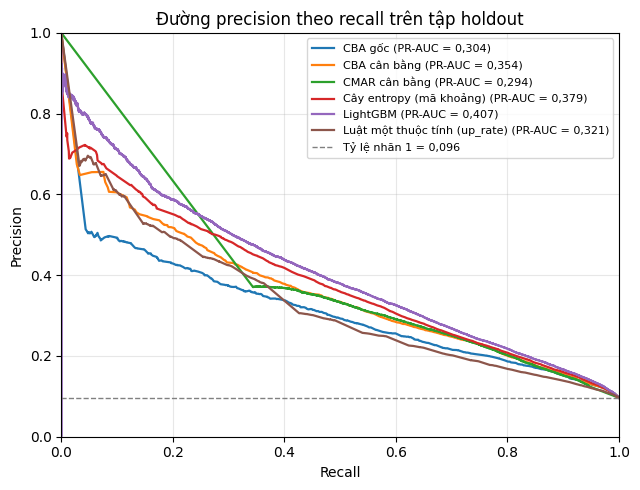

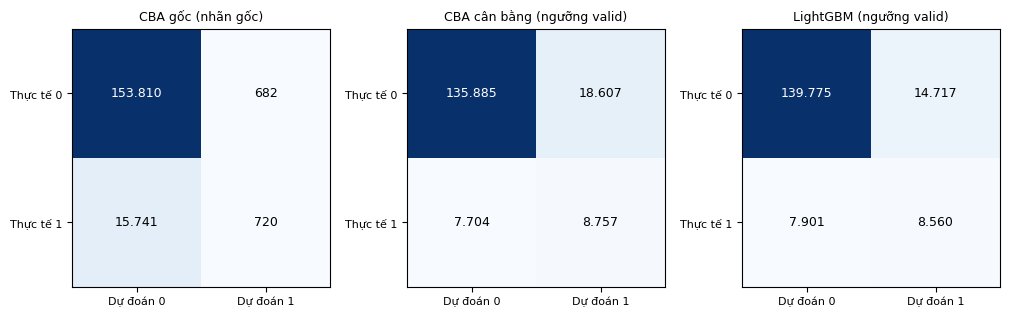

In [16]:
from b5_classification.evaluation import plot_pr_curves, plot_confusion

pr_models = [k for k in ["CBA gốc", "CBA cân bằng", "CMAR cân bằng", "Cây entropy (mã khoảng)", "LightGBM",
                         "Luật một thuộc tính (up_rate)"] if k in scores]
plot_pr_curves(y_hold, {k: scores[k] for k in pr_models}, FIG_DIR / "b5_pr_curves.png",
               "Đường precision theo recall trên tập holdout")
plt.show()
cm_models = {k: preds[k] for k in ["CBA gốc (nhãn gốc)", "CBA cân bằng (ngưỡng valid)", "LightGBM (ngưỡng valid)"] if k in preds}
plot_confusion(y_hold, cm_models, FIG_DIR / "b5_confusion.png")
plt.show()
plt.close("all")

## B9. Luật bước 4 có giúp dự đoán không? (ablation)
So sánh cùng một mô hình khi **có** và **không có** thuộc tính `r4_lift`, chênh lệch tính bằng bootstrap ghép cặp
theo người dùng trên holdout. Khoảng 95% không chứa 0 thì khác biệt có ý nghĩa. Dùng CBA cân bằng (mô hình chính) và LightGBM.

In [17]:
from b5_classification.evaluation import paired_bootstrap_diff

no_r4 = [f for f in FEATURES if f != "r4_lift"]
cba_no = CBAClassifier(PARAMS["cba_min_support"], PARAMS["cba_min_confidence"], PARAMS["cba_max_len"],
                       prune=PARAMS["cba_prune"]).fit(Xc_bal[no_r4], y_bal)
t_no = B.best_f1_threshold(y_valid, cba_no.predict_score(Xc_valid[no_r4]))[0]
s_no = cba_no.predict_score(Xc_hold[no_r4])
lgb_no, _ = B.fit_lightgbm(fit[no_r4], y_fit, valid[no_r4], y_valid, seed=SEED)
tl_no = B.best_f1_threshold(y_valid, lgb_no.predict_proba(valid[no_r4])[:, 1])[0]
sl_no = lgb_no.predict_proba(hold[no_r4])[:, 1]

ablation = pd.concat([
    paired_bootstrap_diff(y_hold, users_hold,
                          {"pred": preds["CBA cân bằng (ngưỡng valid)"], "score": scores["CBA cân bằng"]},
                          {"pred": (s_no >= t_no).astype(int), "score": s_no}, PARAMS["n_boot"], SEED).assign(mo_hinh="CBA cân bằng"),
    paired_bootstrap_diff(y_hold, users_hold,
                          {"pred": preds["LightGBM (ngưỡng valid)"], "score": scores["LightGBM"]},
                          {"pred": (sl_no >= tl_no).astype(int), "score": sl_no}, PARAMS["n_boot"], SEED).assign(mo_hinh="LightGBM"),
])
ablation["so_luat_CBA_co_r4"] = sum(any(cba_bal.feature_names_[a] == "r4_lift" for a, _ in r["items"]) for r in cba_bal.rules_)
ablation.to_csv(OUT_DIR / "b5_ablation_r4.csv", index=False)
r4_match = pd.DataFrame({"khop": df["r4_lift"] > 1, "label": df["label"]}).groupby("khop")["label"].agg(["size", "mean"])
r4_match.to_csv(OUT_DIR / "b5_r4_match.csv")
display(r4_match)
ablation

,size,mean
khop,,
False,681034,0.088173
True,167199,0.135216


,do_do,chenh_lech_trung_vi,can_duoi_95,can_tren_95,mo_hinh,so_luat_CBA_co_r4
0,f1,0.000265,-0.000118,0.000566,CBA cân bằng,145
1,pr_auc,-0.000003,-0.000165,0.000123,CBA cân bằng,145
0,f1,-0.000846,-0.002507,0.001114,LightGBM,145
1,pr_auc,-0.000773,-0.002122,0.000519,LightGBM,145


## B10. Đọc luật CBA (task T43)
Luật của mô hình chính (CBA cân bằng), mỗi luật kèm số dòng và độ chính xác **trên holdout** (luật có còn đúng trên người dùng chưa thấy hay không).
Lưu ý: confidence của CBA cân bằng tính trên phần fit đã cân bằng (tỷ lệ nhãn 1 là 50%), nên không so trực tiếp với tỷ lệ thật.

In [18]:
def rules_with_holdout(m, path):
    fired = m.fired_rule(Xc_hold)
    rt = m.rules_table(LABELERS)
    hs = []
    for k in range(len(m.rules_) + 1):
        msk = fired == (k if k < len(m.rules_) else -1)
        cls = m.rules_[k]["cls_idx"] if k < len(m.rules_) else m.default_idx_
        hs.append({"so_dong_holdout_luat_quyet_dinh": int(msk.sum()),
                   "do_chinh_xac_tren_holdout": float((y_hold[msk] == m.classes_[cls]).mean()) if msk.any() else np.nan})
    rt = pd.concat([rt, pd.DataFrame(hs)], axis=1)
    rt.to_csv(path, index=False)
    return rt

rules_with_holdout(cba, OUT_DIR / "b5_cba_goc_rules.csv")
rt = rules_with_holdout(cba_bal, OUT_DIR / "b5_cba_rules.csv")
if cmar_bal is not None:
    cmar_bal.rules_table(LABELERS, cba_bal.describe_condset).to_csv(OUT_DIR / "b5_cmar_rules.csv", index=False)
rt[(rt["lop"] == 1) & (rt["so_dong_holdout_luat_quyet_dinh"] >= 100)].head(15)

,thu_tu,dieu_kien,lop,support,confidence,so_dong_phu_khi_chon,so_dong_dung_khi_chon,tong_loi_tich_luy,so_dong_holdout_luat_quyet_dinh,do_chinh_xac_tren_holdout
0,1,"up_n_bought >= 15,5 VÀ up_rate >= 0,503 VÀ up_...",1,0.015104,0.960968,1819.0,1748.0,56188.0,679,0.674521
1,2,"up_n_bought >= 15,5 VÀ up_orders_since_last < ...",1,0.012443,0.956811,355.0,329.0,55885.0,173,0.543353
4,5,"up_rate >= 0,503 VÀ up_orders_since_last < 0,5...",1,0.014750,0.950975,1089.0,1025.0,54924.0,522,0.666667
7,8,"up_n_bought [6,5; 15,5) VÀ up_orders_since_las...",1,0.014007,0.949619,1366.0,1297.0,53696.0,525,0.657143
11,12,"up_n_bought >= 15,5 VÀ up_rate >= 0,503 VÀ a_r...",1,0.010697,0.947933,327.0,292.0,53259.0,165,0.454545
12,13,"up_n_bought >= 15,5 VÀ up_rate >= 0,503 VÀ up_...",1,0.019088,0.947662,264.0,231.0,53061.0,100,0.360000
13,14,"up_rate >= 0,503 VÀ up_orders_since_last < 0,5...",1,0.017619,0.947491,990.0,930.0,52191.0,368,0.597826
18,19,"up_rate >= 0,503 VÀ up_orders_since_last < 0,5...",1,0.025896,0.944830,1253.0,1157.0,51130.0,567,0.534392
24,25,"up_n_bought >= 15,5 VÀ up_days_since_last < 30...",1,0.015847,0.941962,217.0,190.0,50880.0,142,0.316901
27,28,"up_rate >= 0,503 VÀ up_days_since_last < 30,5 ...",1,0.021213,0.940974,285.0,261.0,50585.0,127,0.511811


## B11. Phân tích lỗi theo nhóm người dùng, nhóm sản phẩm (CBA cân bằng so với LightGBM)

In [19]:
from b5_classification.evaluation import error_by_group

dept_name = hold[["product_id"]].merge(d.products[["product_id", "department"]], on="product_id", how="left")["department"]
groups = {
    "nhom_so_don_prior": pd.cut(hold["u_n_orders"], [0, 5, 10, 20, 50, 100], labels=["3-5", "6-10", "11-20", "21-50", "51-99"]),
    "so_lan_da_mua": pd.cut(hold["up_n_bought"], [0, 1, 2, 5, 1000], labels=["1", "2", "3-5", "6+"]),
    "nganh_hang": dept_name,
}
err_tables = {}
for gname, g in groups.items():
    t = error_by_group(y_hold, preds["CBA cân bằng (ngưỡng valid)"], g, gname).add_prefix("CBA_").rename(columns={f"CBA_{gname}": gname})
    t2 = error_by_group(y_hold, preds["LightGBM (ngưỡng valid)"], g, gname)[["f1"]].rename(columns={"f1": "LightGBM_f1"})
    err_tables[gname] = pd.concat([t, t2], axis=1)
    err_tables[gname].to_csv(OUT_DIR / f"b5_error_{gname}.csv", index=False)
err_tables["nhom_so_don_prior"]

,nhom_so_don_prior,CBA_so_cap,CBA_ty_le_nhan_1,CBA_precision,CBA_recall,CBA_f1,CBA_duong_tinh_gia,CBA_am_tinh_gia,LightGBM_f1
0,3-5,19467,0.160374,0.331525,0.567585,0.418566,3573,1350,0.441885
1,6-10,32940,0.127747,0.348142,0.478612,0.403082,3771,2194,0.433120
2,11-20,41934,0.098536,0.347431,0.508955,0.412960,3950,2029,0.440089
3,21-50,51381,0.073471,0.305129,0.557881,0.394493,4796,1669,0.424047
4,51-99,25231,0.048512,0.232388,0.622549,0.338441,2517,462,0.383866


In [20]:
err_tables["so_lan_da_mua"]

,so_lan_da_mua,CBA_so_cap,CBA_ty_le_nhan_1,CBA_precision,CBA_recall,CBA_f1,CBA_duong_tinh_gia,CBA_am_tinh_gia,LightGBM_f1
0,1,102237,0.047380,0.183349,0.157308,0.169333,3394,4082,0.159190
1,2,28582,0.101462,0.279678,0.383448,0.323444,2864,1788,0.346154
2,3-5,25451,0.173431,0.334415,0.676937,0.447674,5947,1426,0.469985
3,6+,14683,0.293060,0.378266,0.905182,0.533562,6402,408,0.574001


In [21]:
err_tables["nganh_hang"].sort_values("CBA_so_cap", ascending=False).head(12)

,nganh_hang,CBA_so_cap,CBA_ty_le_nhan_1,CBA_precision,CBA_recall,CBA_f1,CBA_duong_tinh_gia,CBA_am_tinh_gia,LightGBM_f1
19,produce,42151,0.128538,0.325478,0.583795,0.417944,6555,2255,0.448791
7,dairy eggs,22860,0.125328,0.320696,0.643630,0.428091,3906,1021,0.458096
16,pantry,15788,0.038447,0.210606,0.228995,0.219416,521,468,0.251462
20,snacks,15234,0.087961,0.328497,0.473134,0.387768,1296,706,0.415260
10,frozen,13263,0.083465,0.328930,0.449864,0.380008,1016,609,0.412064
3,beverages,12329,0.124503,0.344008,0.650814,0.450101,1905,536,0.489125
6,canned goods,7663,0.060029,0.272085,0.334783,0.300195,412,306,0.342016
9,dry goods pasta,6060,0.063531,0.244770,0.303896,0.271147,361,268,0.311585
11,household,5624,0.053876,0.248227,0.231023,0.239316,212,233,0.278095
2,bakery,5535,0.108762,0.327024,0.516611,0.400515,640,291,0.440260


## B12. Mức quan trọng thuộc tính của LightGBM (để đối chiếu với các thuộc tính xuất hiện trong luật CBA)

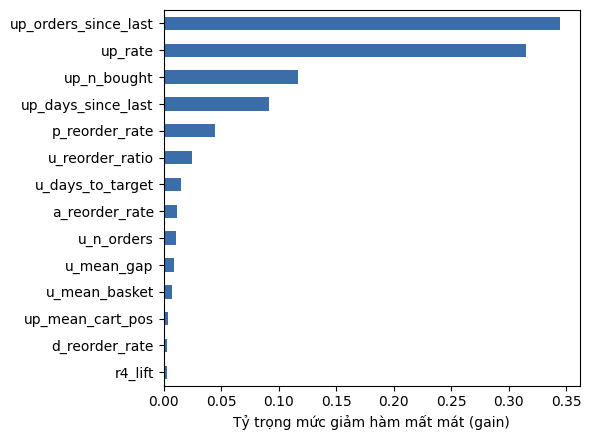

,ty_trong_gain_LightGBM,so_luat_CBA_chua_thuoc_tinh
up_orders_since_last,0.344338,386
up_rate,0.315323,296
up_n_bought,0.117100,380
up_days_since_last,0.091695,344
p_reorder_rate,0.044334,322
u_reorder_ratio,0.024822,220
u_days_to_target,0.015128,196
a_reorder_rate,0.011262,200
u_n_orders,0.010654,244
u_mean_gap,0.008668,239


In [22]:
plt.close("all")                      # tránh vẽ chồng lên hình của ô trước
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=FEATURES).sort_values()
fig_imp, ax = plt.subplots(figsize=(6, 4.5))
(imp / imp.sum()).plot.barh(ax=ax, color="#3b6ea8")
ax.set_xlabel("Tỷ trọng mức giảm hàm mất mát (gain)")
fig_imp.tight_layout(); fig_imp.savefig(FIG_DIR / "b5_lgbm_importance.png", dpi=200); plt.show()
in_cba = pd.Series({f: sum(any(cba_bal.feature_names_[a] == f for a, _ in r["items"]) for r in cba_bal.rules_) for f in FEATURES},
                   name="so_luat_CBA_chua_thuoc_tinh")
imp_tab = pd.concat([(imp / imp.sum()).rename("ty_trong_gain_LightGBM"), in_cba], axis=1).sort_values("ty_trong_gain_LightGBM", ascending=False)
imp_tab.to_csv(OUT_DIR / "b5_importance_vs_cba.csv")
imp_tab

## B13. Lưu thông tin lần chạy (để tái lập)

In [23]:
import sklearn, scipy
try:
    import lightgbm; lgb_ver = lightgbm.__version__
except Exception:
    lgb_ver = None
run_info = {
    "thoi_diem": time.strftime("%Y-%m-%d %H:%M:%S"), "seed": SEED, "params": PARAMS,
    "nguon_luat_buoc_4": rules4_source, "so_luat_buoc_4_dung": int(len(rules4)),
    "phien_ban": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                  "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "lightgbm": lgb_ver},
    "so_cap_fit_can_bang": int(len(y_bal)),
    "cba_goc": cba_info, "cba_minsup_theo_lop": cba_ms_info, "cba_can_bang": cba_bal_info,
    "cmar_goc": cmar_info, "cmar_can_bang": cmar_bal_info,
    "lightgbm_so_cay": int(lgbm.best_iteration_), "cay_ma_khoang_do_sau": int(tree_disc.get_depth()),
    "cay_goc_do_sau": int(tree_raw.get_depth()),
    "thoi_gian_huan_luyen_s": {"cay_ma_khoang": t_tree_disc, "cay_goc": t_tree_raw, "lightgbm": t_lgbm},
    "nguong_valid": thresholds, "diem_so_suy_bien": sorted(degenerate),
}
with open(OUT_DIR / "b5_run_info.json", "w", encoding="utf-8") as fh:
    json.dump(run_info, fh, ensure_ascii=False, indent=2, default=float)
print(json.dumps(run_info, ensure_ascii=False, indent=1, default=float)[:2500])

{
 "thoi_diem": "2026-10-27 07:35:39",
 "seed": 42,
 "params": {
  "holdout_frac": 0.2,
  "valid_frac": 0.1,
  "max_intervals": 5,
  "cba_min_support": 0.01,
  "cba_min_confidence": 0.5,
  "cba_max_len": 3,
  "cba_prune": true,
  "cmar_coverage_delta": 4,
  "run_cmar": true,
  "n_boot": 200
 },
 "nguon_luat_buoc_4": "B4",
 "so_luat_buoc_4_dung": 25,
 "phien_ban": {
  "python": "3.13.16",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "scikit-learn": "1.6.1",
  "scipy": "1.16.3",
  "lightgbm": "4.6.0"
 },
 "so_cap_fit_can_bang": 115730,
 "cba_goc": {
  "so_condset_pho_bien": 9607,
  "so_CAR": 9607,
  "so_luat_sau_cat_tia": 1803,
  "so_luat_trong_bo_phan_lop": 1426,
  "so_luat_lop_1_trong_bo_phan_lop": 0,
  "lop_mac_dinh": 1,
  "rule_generation_s": 3.25,
  "pruning_s": 0.32,
  "classifier_building_s": 7.04
 },
 "cba_minsup_theo_lop": {
  "so_condset_pho_bien": 13346,
  "so_CAR": 10675,
  "so_luat_sau_cat_tia": 2107,
  "so_luat_trong_bo_phan_lop": 1485,
  "so_luat_lop_1_trong_bo_phan_lop": 0,

In [24]:
  !pip freeze | grep -iE "pandas|numpy|scipy|scikit-learn|lightgbm|pyarrow|matplotlib|seaborn|duckdb|mlxtend|pytest"

duckdb==1.3.2
geopandas==1.2.0
lightgbm==4.6.0
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
mlxtend==0.23.4
numpy==2.1.3
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
pyarrow==23.0.1
pytest==8.4.2
scikit-learn==1.6.1
scipy==1.16.3
seaborn==0.13.2
sklearn-pandas==2.2.0
